# Laboratorio 5 — Ejercicio 1

## Algoritmo genético para el problema del agente viajero (TSP)

El ejercicio pide diseñar un algoritmo genético que resuelva el problema del agente viajero. En este problema hay una lista de ciudades y se busca el camino más corto que pase por todas una sola vez y regrese al punto de partida.

El algoritmo tiene que aceptar dos formas de entrada. Una es un archivo o listado con las coordenadas $(x, y)$ de las ciudades. La otra es un archivo o matriz simétrica de distancias $D = [d_{ij}]$, donde $d_{ij}$ es la distancia entre la ciudad $i$ y la ciudad $j$.

También se pide que el usuario pueda cambiar el tamaño de la población $N$, el número máximo de iteraciones `maxIter`, el tipo de selección con sus parámetros, y qué parte de la población se crea por cruce y por mutación. Además hay que cuidar que la población no se vuelva toda igual demasiado rápido.

Al final el algoritmo tiene que mostrar una simulación de cómo va cambiando el mejor recorrido, una gráfica de cómo baja la distancia, y devolver el mejor recorrido `best` con su distancia total $D$.

## Resumen del ejercicio

Un recorrido se guarda como una lista con todas las ciudades en el orden en que se visitan. El algoritmo trabaja con una población de $N$ recorridos. En cada generación arma una población nueva con cuatro grupos. El primero son los mejores recorridos, que pasan sin cambios. El segundo son los hijos que salen de cruzar dos recorridos. El tercero son recorridos a los que se les aplica una mutación. El cuarto son recorridos nuevos al azar, que solo se usan si sobra espacio.

El cuaderno arma el algoritmo por partes. Primero va la lectura de la entrada y el cálculo de la distancia de un recorrido. Después van la selección, el cruce, la mutación y el cuidado de la diversidad. Con esas piezas se arma la función principal, que se llama `algoritmo_genetico_tsp`. Las últimas secciones son para probar la función con ejemplos y comparar sus opciones.

## Objetivo y referencias

El objetivo es programar el algoritmo genético con NumPy, sin usar librerías que ya resuelvan el problema. matplotlib se usa para las gráficas y para la animación del recorrido.

Los operadores de selección, cruce y mutación son los que se vieron en clase. Para repasar algunos detalles también se usaron de apoyo estas páginas.

- [Problema del viajante](https://es.wikipedia.org/wiki/Problema_del_viajante), con la descripción del problema.
- [Selection (evolutionary algorithm)](https://en.wikipedia.org/wiki/Selection_(evolutionary_algorithm)), sobre los tipos de selección.
- [Crossover (evolutionary algorithm)](https://en.wikipedia.org/wiki/Crossover_(evolutionary_algorithm)), con los cruces OX y PMX para recorridos.
- [Mutation (evolutionary algorithm)](https://en.wikipedia.org/wiki/Mutation_(evolutionary_algorithm)), con las mutaciones para recorridos.
- [2-opt](https://en.wikipedia.org/wiki/2-opt), sobre cómo se quita un cruce de un recorrido al darle vuelta a un tramo.
- [Multidimensional scaling](https://en.wikipedia.org/wiki/Multidimensional_scaling), sobre cómo ubicar puntos a partir de sus distancias.
- [FuncAnimation de matplotlib](https://matplotlib.org/stable/api/_as_gen/matplotlib.animation.FuncAnimation.html), que es la herramienta usada para la animación.

## 1. Diseño del algoritmo

### Cómo se representa un recorrido

Las $n$ ciudades se numeran de $0$ a $n-1$. Un recorrido es una lista $x = [x_1, x_2, \ldots, x_n]$ que tiene todas las ciudades sin repetir ninguna, en el orden en que se visitan. Esa lista es el cromosoma, y a este tipo de lista se le llama permutación. Como el recorrido regresa a la ciudad donde empezó, su distancia total es

$$D(x) = \sum_{i=1}^{n-1} d(x_i, x_{i+1}) + d(x_n, x_1)$$

### Fitness

El fitness dice qué tan bueno es un recorrido. Se usa el que se vio en clase para este problema, que es $f(x) = \dfrac{1}{D(x)}$. Entre más corto es el recorrido, más grande es su fitness. Entonces ordenar la población de menor a mayor distancia es lo mismo que ordenarla de mayor a menor fitness. Cualquier lista que tenga todas las ciudades una sola vez es un recorrido válido, así que no hace falta castigar soluciones malas con una penalización.

### Cómo se arma cada generación

La idea es mantener la población ordenada, con el mejor recorrido en la posición 0. La generación siguiente se forma con estos grupos.

| Grupo | Tamaño | Cómo se crea |
|---|---|---|
| Sobrevivientes | $s \cdot N$ | Los mejores recorridos pasan sin cambios (elitismo) |
| Cruce | $c \cdot N$ | Se escogen dos padres y se combinan con un operador de cruce |
| Mutación | $m \cdot N$ | Se escoge un individuo y se le aplica un operador de mutación |
| Inmigrantes | lo que falte para llegar a $N$ | Recorridos nuevos al azar |

Si $s + c + m = 1$ no hay inmigrantes. Si la suma es menor que 1, lo que falta se llena con recorridos al azar. Esto ayuda a que entren recorridos distintos a la población.

### Parámetros que puede cambiar el usuario

| Parámetro | Significado | Valor si no se indica |
|---|---|---|
| `entrada` | Archivo o listado de coordenadas, o archivo o matriz de distancias | |
| `N` | Tamaño de la población | 200 |
| `maxIter` | Número máximo de iteraciones (generaciones) | 1000 |
| `seleccion` | Tipo de selección, que puede ser `"torneo"`, `"ranking"`, `"fitness"` o `"elitismo"` | `"torneo"` |
| `k` | Tamaño del torneo | 3 |
| `s` | Tamaño o porcentaje de sobrevivientes por elitismo | 0.05 |
| `f` | Forma de repartir la probabilidad en la selección por ranking o por fitness | lineal en ranking, $1/D$ en fitness |
| `c` | Tamaño o porcentaje de la población creada por cruce | 0.70 |
| `m` | Tamaño o porcentaje de la población creada por mutación | 0.25 |
| `cruce` | Operador de cruce, que puede ser `"ox"` o `"pmx"` | `"ox"` |
| `mutacion` | Operador de mutación, que puede ser `"inversion"`, `"intercambio"`, `"insercion"` o `"mezcla"` | `"inversion"` |
| `evitar_clones` | Activa el control de recorridos repetidos | `True` |
| `semilla` | Semilla del generador de números al azar, para poder repetir una corrida | `None` |

Los parámetros `s`, `c` y `m` se pueden escribir como un porcentaje entre 0 y 1 o como una cantidad entera de individuos.

In [1]:
import time
from itertools import permutations
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML

plt.rcParams["animation.embed_limit"] = 40

### Explicación de esta parte

NumPy guarda la población como una tabla de $N$ filas y $n$ columnas, donde cada fila es un recorrido. Así se puede calcular la distancia de todos los recorridos de una sola vez. `permutations` sirve para hacer la lista de todos los recorridos posibles de un problema pequeño, y solo se usa en la sección de verificación. `FuncAnimation` y `PillowWriter` sirven para crear la animación y guardarla como GIF. `HTML` sirve para mostrarla dentro del cuaderno. La última línea sube el límite de tamaño que matplotlib permite para una animación dentro del cuaderno.

## 2. Entrada del problema

La función `cargar_problema` recibe cualquiera de las dos formas de entrada que pide el enunciado. Siempre devuelve la matriz de distancias, porque eso es lo único que el algoritmo necesita para trabajar. Si la entrada fue un listado de coordenadas, también las devuelve para poder dibujar el recorrido.

In [2]:
def matriz_de_distancias(coordenadas, redondear=False):
    """Distancia euclidiana entre todas las parejas de ciudades."""
    coordenadas = np.asarray(coordenadas, dtype=float)
    diferencias = coordenadas[:, None, :] - coordenadas[None, :, :]
    matriz = np.sqrt((diferencias ** 2).sum(axis=2))
    return np.floor(matriz + 0.5) if redondear else matriz


def leer_archivo(ruta):
    """Lee las filas numéricas de un archivo de texto, CSV o TSPLIB."""
    filas = []
    for linea in Path(ruta).read_text().splitlines():
        partes = linea.replace(",", " ").replace(";", " ").split()
        try:
            numeros = [float(parte) for parte in partes]
        except ValueError:
            continue  # encabezados y líneas de texto
        if numeros:
            filas.append(numeros)
    return filas


def cargar_problema(entrada, tipo=None, redondear=False):
    """Devuelve (matriz de distancias, coordenadas).

    `entrada` puede ser la ruta de un archivo o un listado. Las coordenadas
    son None cuando la entrada es una matriz de distancias.
    """
    if isinstance(entrada, (str, Path)):
        entrada = leer_archivo(entrada)
    try:
        datos = np.asarray(entrada, dtype=float)
    except ValueError:
        raise ValueError("Todas las filas deben tener la misma cantidad de números.")
    if datos.ndim != 2:
        raise ValueError("La entrada debe ser una tabla de coordenadas o una matriz de distancias.")

    filas, columnas = datos.shape
    parece_matriz = (
        filas == columnas
        and np.allclose(datos, datos.T)
        and np.allclose(np.diag(datos), 0)
    )
    if tipo is None:
        tipo = "matriz" if parece_matriz else "coordenadas"

    if tipo == "matriz":
        if not parece_matriz:
            raise ValueError("La matriz debe ser cuadrada, simétrica y con ceros en la diagonal.")
        return datos, None
    if tipo == "coordenadas":
        if columnas == 3:
            datos = datos[:, 1:]  # la primera columna es el número de ciudad
        if datos.shape[1] != 2:
            raise ValueError("Las coordenadas deben tener dos columnas (x, y).")
        return matriz_de_distancias(datos, redondear), datos
    raise ValueError("tipo debe ser 'coordenadas' o 'matriz'.")


def posiciones_aproximadas(matriz):
    """Ubica las ciudades en el plano a partir de la matriz de distancias (MDS clásico)."""
    n = len(matriz)
    centrado = np.eye(n) - np.ones((n, n)) / n
    B = -0.5 * centrado @ (matriz ** 2) @ centrado
    valores, vectores = np.linalg.eigh(B)
    mayores = np.argsort(valores)[::-1][:2]
    return vectores[:, mayores] * np.sqrt(np.maximum(valores[mayores], 0))


cuadrado = [(0, 0), (10, 0), (10, 10), (0, 10)]
matriz_cuadrado, coordenadas_cuadrado = cargar_problema(cuadrado)
print("Entrada como listado de coordenadas")
print(np.round(matriz_cuadrado, 2))

matriz_leida, coordenadas_leidas = cargar_problema(matriz_cuadrado)
print("\nEntrada como matriz de distancias")
print("Se obtiene la misma matriz:", np.array_equal(matriz_leida, matriz_cuadrado))
print("Coordenadas disponibles:", coordenadas_leidas)

Entrada como listado de coordenadas
[[ 0.   10.   14.14 10.  ]
 [10.    0.   10.   14.14]
 [14.14 10.    0.   10.  ]
 [10.   14.14 10.    0.  ]]

Entrada como matriz de distancias
Se obtiene la misma matriz: True
Coordenadas disponibles: None


### Explicación de esta parte

`matriz_de_distancias` calcula la distancia en línea recta entre todas las parejas de ciudades. La opción `redondear` aproxima cada distancia al entero más cercano. Así vienen calculadas las distancias en los problemas de la colección TSPLIB, y con esta opción un resultado se puede comparar con el mejor valor que ya se conoce para esos problemas.

`leer_archivo` se queda solo con las líneas que tienen puros números. Por eso sirve para un archivo de texto, para un CSV y también para un archivo `.tsp` de TSPLIB que traiga coordenadas, porque las líneas de encabezado se saltan.

`cargar_problema` revisa qué tipo de entrada recibió. Si la tabla es cuadrada, simétrica y tiene ceros en la diagonal, la toma como matriz de distancias. Si no cumple eso, la toma como coordenadas. Cuando hay tres columnas se quita la primera, porque es el número de la ciudad. Con el parámetro `tipo` el usuario puede decir directamente qué tipo de entrada es.

Cuando la entrada es una matriz no hay coordenadas para dibujar. Para eso está `posiciones_aproximadas`, que usa una técnica llamada escalamiento multidimensional. Esta técnica busca puntos en un plano que guarden entre ellos distancias parecidas a las de la matriz. Esas posiciones solo se usan para las gráficas. Para calcular, el algoritmo siempre usa las distancias de la matriz original.

La prueba usa un cuadrado de lado 10. En la matriz se ven los lados de 10 y las diagonales de 14.14. Al entregar esa misma matriz como entrada, la función la reconoce como matriz de distancias y avisa que no hay coordenadas.

## 3. Distancia de un recorrido y población inicial

La distancia total de un recorrido es lo que el algoritmo quiere hacer más pequeño. La población inicial se forma con recorridos al azar.

In [3]:
def longitudes(poblacion, matriz):
    """Distancia total de cada recorrido, contando el regreso a la ciudad inicial."""
    poblacion = np.atleast_2d(poblacion)
    siguiente = np.roll(poblacion, -1, axis=1)
    return matriz[poblacion, siguiente].sum(axis=1)


def poblacion_inicial(N, n, rng):
    """N recorridos aleatorios sobre n ciudades."""
    return rng.permuted(np.tile(np.arange(n), (N, 1)), axis=1)


recorridos_prueba = np.array([[0, 1, 2, 3], [0, 2, 1, 3]])
print("Distancias de dos recorridos del cuadrado:", np.round(longitudes(recorridos_prueba, matriz_cuadrado), 2))
print("\nPoblación inicial de 3 recorridos con 6 ciudades")
print(poblacion_inicial(3, 6, np.random.default_rng(0)))

Distancias de dos recorridos del cuadrado: [40.   48.28]

Población inicial de 3 recorridos con 6 ciudades
[[3 2 5 4 0 1]
 [4 5 1 2 0 3]
 [3 2 0 5 4 1]]


### Explicación de esta parte

`longitudes` recibe toda la población de una vez. `np.roll` corre cada recorrido una posición, y así cada ciudad queda en pareja con la que sigue y la última queda en pareja con la primera. Con esas parejas se buscan las distancias en la matriz y se suman por fila.

En el cuadrado, el recorrido `0, 1, 2, 3` pasa por los cuatro lados y mide 40. El recorrido `0, 2, 1, 3` usa las dos diagonales y mide 48.28. El primero es mejor porque es más corto, y su fitness $1/D$ es más grande.

`poblacion_inicial` crea $N$ filas con las ciudades en orden y después revuelve cada fila por separado. Entonces cada fila tiene todas las ciudades una sola vez.

## 4. Operadores de selección

La selección decide qué individuos se usan como padres en el cruce y cuáles se usan como base para la mutación. Se programan los cuatro tipos que pide el enunciado. Todos trabajan con la población ordenada de menor a mayor distancia, o sea que la posición 0 es la del mejor recorrido.

| Tipo | Cómo escoge | Parámetro |
|---|---|---|
| `"torneo"` | Toma `k` individuos al azar y se queda con el mejor | `k` |
| `"ranking"` | La probabilidad depende del lugar que ocupa el individuo en la población ordenada | `f` |
| `"fitness"` | La probabilidad es proporcional al fitness (ruleta) | `f` |
| `"elitismo"` | Escoge al azar solo entre los `s·N` mejores | `s` |

In [4]:
def pesos_por_ranking(N, f=None):
    """Peso de cada posición del ordenamiento (posición 0 = mejor individuo)."""
    posicion = np.arange(N)
    if callable(f):
        return np.asarray(f(posicion), dtype=float)
    if f in (None, "lineal"):
        return (N - posicion).astype(float)  # el mejor pesa N y el peor pesa 1
    if f == "exponencial":
        return 0.5 ** (10 * posicion / N)  # el peso baja a la mitad cada 10 % del ordenamiento
    raise ValueError("f debe ser 'lineal', 'exponencial' o una función.")


def pesos_por_fitness(distancias, f=None):
    """Peso de cada individuo según su distancia."""
    if callable(f):
        return np.asarray(f(distancias), dtype=float)
    if f in (None, "inversa"):
        return 1.0 / (distancias + 1e-12)  # fitness de clase, f = 1/D
    if f == "ventana":
        return distancias.max() - distancias + 1e-12  # fitness medido respecto al peor
    raise ValueError("f debe ser 'inversa', 'ventana' o una función.")


def seleccionar(distancias, cuantos, rng, seleccion="torneo", k=3, f=None, n_elite=2):
    """Devuelve las posiciones de `cuantos` individuos elegidos.

    Supone que `distancias` está ordenado de menor a mayor.
    """
    N = len(distancias)
    if seleccion == "torneo":
        participantes = rng.integers(0, N, size=(cuantos, k))
        return participantes.min(axis=1)  # la posición menor es la de menor distancia
    if seleccion == "elitismo":
        return rng.integers(0, max(n_elite, 2), size=cuantos)
    if seleccion == "ranking":
        pesos = pesos_por_ranking(N, f)
    elif seleccion == "fitness":
        pesos = pesos_por_fitness(distancias, f)
    else:
        raise ValueError("seleccion debe ser 'torneo', 'ranking', 'fitness' o 'elitismo'.")
    return rng.choice(N, size=cuantos, p=pesos / pesos.sum())

### Explicación de esta parte

En el torneo se sortean `k` posiciones por cada individuo que se necesita, y gana la posición más pequeña porque la población está ordenada. Entre más grande es `k`, más ventaja tienen los mejores.

En el ranking la probabilidad depende solo del lugar que ocupa el individuo. Con `f="lineal"` el mejor recibe un peso de $N$ y el peor recibe un peso de 1. Con `f="exponencial"` el peso baja a la mitad cada vez que se avanza un 10 % de la lista, y entonces la selección se carga más hacia los primeros lugares.

En la selección por fitness, que también se conoce como ruleta, la probabilidad de cada individuo es $P(i) = f_i / \sum_j f_j$. Con `f="inversa"` se usa $f_i = 1/D_i$. Con `f="ventana"` se usa $f_i = D_{\max} - D_i$, que mide qué tanto mejor es cada recorrido comparado con el peor de la población.

En los dos casos `f` también puede ser una función escrita por el usuario que devuelva los pesos. Así el usuario puede definir su propia forma de repartir la probabilidad.

Con el elitismo los padres se escogen al azar y todos con la misma probabilidad, pero solo entre los `s·N` mejores.

En la siguiente celda se hace una gráfica para ver cuántas veces escoge cada tipo de selección a cada posición de una población de 50 recorridos.

Torneo (k = 3)         el mejor se elige  5.82 % de las veces y el peor  0.00 %
Ranking lineal         el mejor se elige  3.85 % de las veces y el peor  0.09 %
Fitness (1/D)          el mejor se elige  2.49 % de las veces y el peor  1.77 %
Elitismo (10 mejores)  el mejor se elige 10.03 % de las veces y el peor  0.00 %


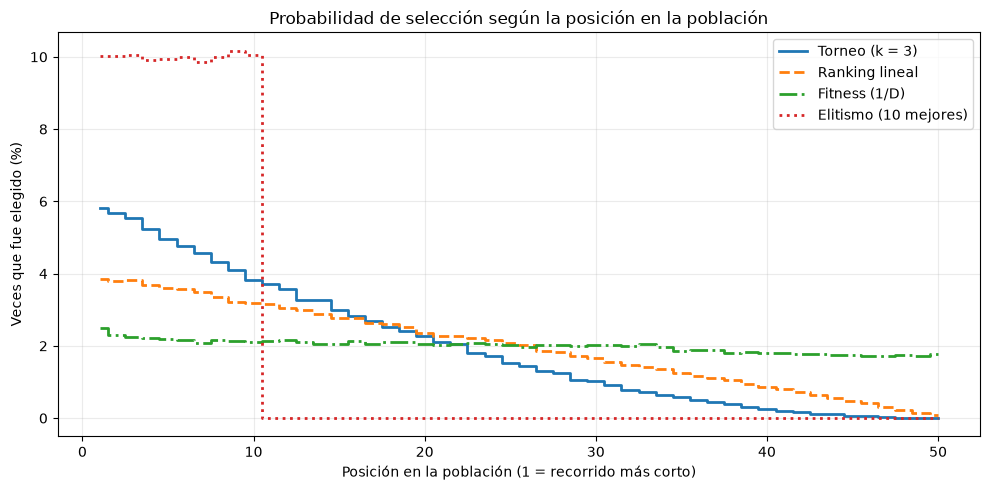

In [5]:
rng_demo = np.random.default_rng(0)
ciudades_demo = rng_demo.uniform(0, 100, size=(20, 2))
poblacion_demo = poblacion_inicial(50, 20, rng_demo)
distancias_demo = np.sort(longitudes(poblacion_demo, matriz_de_distancias(ciudades_demo)))

esquemas_demo = [
    ("Torneo (k = 3)", dict(seleccion="torneo", k=3), "-"),
    ("Ranking lineal", dict(seleccion="ranking"), "--"),
    ("Fitness (1/D)", dict(seleccion="fitness"), "-."),
    ("Elitismo (10 mejores)", dict(seleccion="elitismo", n_elite=10), ":"),
]

plt.figure(figsize=(10, 5))
for nombre, opciones, estilo in esquemas_demo:
    elegidos = seleccionar(distancias_demo, 200_000, rng_demo, **opciones)
    frecuencia = 100 * np.bincount(elegidos, minlength=50) / len(elegidos)
    plt.plot(np.arange(1, 51), frecuencia, estilo, linewidth=2, drawstyle="steps-mid", label=nombre)
    print(f"{nombre:22s} el mejor se elige {frecuencia[0]:5.2f} % de las veces y el peor {frecuencia[-1]:5.2f} %")

plt.title("Probabilidad de selección según la posición en la población")
plt.xlabel("Posición en la población (1 = recorrido más corto)")
plt.ylabel("Veces que fue elegido (%)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Explicación de esta parte

Se arma una población de 50 recorridos al azar y a cada tipo de selección se le pide escoger 200 000 veces. La altura de cada línea es el porcentaje de veces que salió cada posición. Si todos tuvieran la misma probabilidad, cada posición saldría el 2 % de las veces.

El torneo con $k = 3$ escoge al mejor en el 5.82 % de los casos y casi nunca escoge al peor. El ranking lineal baja en línea recta desde 3.85 % hasta 0.09 %. El elitismo reparte todo entre los 10 primeros, con cerca de 10 % para cada uno, y deja a los demás en cero.

La selección por fitness con $1/D$ sale casi plana. El mejor sale el 2.49 % de las veces y el peor el 1.77 %. Esto pasa porque las distancias de los recorridos son números de tamaño parecido, y entonces sus inversos también se parecen mucho. Con este tipo de selección los mejores recorridos tienen muy poca ventaja sobre los demás.

## 5. Operadores de cruce

El cruce de un punto o de dos puntos que se usa con ceros y unos no sirve para recorridos, porque el hijo puede salir con ciudades repetidas y con otras que faltan. Por eso se programan dos cruces que se vieron en clase y que están hechos para este tipo de listas.

- El cruce OX (Order Crossover) copia en el hijo un tramo del primer padre. Los espacios que quedan se llenan con las ciudades que faltan, en el orden en que aparecen en el segundo padre, empezando después del segundo punto de corte.
- El cruce PMX (Partially Mapped Crossover) copia en el hijo un tramo del primer padre y el resto lo toma del segundo padre. Las ciudades que quedarían repetidas se cambian usando la relación entre los dos tramos.

In [6]:
def cruce_ox(p1, p2, a, b):
    """Order Crossover: tramo [a, b) de p1 y el resto en el orden de p2."""
    n = len(p1)
    hijo = np.empty(n, dtype=p1.dtype)
    hijo[a:b] = p1[a:b]

    usado = np.zeros(n, dtype=bool)
    usado[p1[a:b]] = True
    orden_p2 = np.concatenate((p2[b:], p2[:b]))  # p2 leído desde el segundo corte
    faltantes = orden_p2[~usado[orden_p2]]

    hijo[b:] = faltantes[: n - b]
    hijo[:a] = faltantes[n - b:]
    return hijo


def cruce_pmx(p1, p2, a, b):
    """Partially Mapped Crossover: tramo [a, b) de p1 y el resto de p2."""
    n = len(p1)
    hijo = p2.copy()
    hijo[a:b] = p1[a:b]

    en_tramo = np.zeros(n, dtype=bool)
    en_tramo[p1[a:b]] = True
    mapa = np.empty(n, dtype=p1.dtype)
    mapa[p1[a:b]] = p2[a:b]  # ciudad del tramo de p1 -> ciudad de p2 en esa posición

    posiciones = np.arange(n)
    fuera_del_tramo = (posiciones < a) | (posiciones >= b)
    for i in posiciones[fuera_del_tramo & en_tramo[p2]]:  # posiciones con ciudad repetida
        ciudad = p2[i]
        while en_tramo[ciudad]:
            ciudad = mapa[ciudad]
        hijo[i] = ciudad
    return hijo


CRUCES = {"ox": cruce_ox, "pmx": cruce_pmx}

padre_1 = np.array([0, 1, 2, 3, 4, 5, 6, 7])
padre_2 = np.array([3, 6, 1, 7, 0, 4, 2, 5])
print("Padre 1 :", padre_1)
print("Padre 2 :", padre_2)
print("Tramo copiado del padre 1 (posiciones 2 a 4):", padre_1[2:5])
print("Hijo OX :", cruce_ox(padre_1, padre_2, 2, 5))
print("Hijo PMX:", cruce_pmx(padre_1, padre_2, 2, 5))

rng_prueba = np.random.default_rng(1)
for _ in range(5000):
    n = int(rng_prueba.integers(3, 30))
    p1, p2 = rng_prueba.permutation(n), rng_prueba.permutation(n)
    a, b = np.sort(rng_prueba.integers(0, n, size=2))
    for operador in CRUCES.values():
        hijo = operador(p1, p2, a, b + 1)
        assert np.array_equal(np.sort(hijo), np.arange(n))
        assert np.array_equal(hijo[a:b + 1], p1[a:b + 1])
print("\n5000 parejas aleatorias: todos los hijos de OX y PMX son permutaciones válidas.")

Padre 1 : [0 1 2 3 4 5 6 7]
Padre 2 : [3 6 1 7 0 4 2 5]
Tramo copiado del padre 1 (posiciones 2 a 4): [2 3 4]
Hijo OX : [7 0 2 3 4 5 6 1]
Hijo PMX: [7 6 2 3 4 0 1 5]

5000 parejas aleatorias: todos los hijos de OX y PMX son permutaciones válidas.


### Explicación de esta parte

Los puntos de corte entran como los parámetros `a` y `b`, y el tramo que se copia va de la posición `a` a la posición `b - 1`. Cuando la función se usa dentro del algoritmo completo, estos puntos se sortean para cada hijo.

En el ejemplo, el tramo que se copia del padre 1 es `2, 3, 4`.

En OX se lee el padre 2 empezando en el segundo corte, y eso da `4, 2, 5, 3, 6, 1, 7, 0`. Al quitar las ciudades que ya están en el tramo queda `5, 6, 1, 7, 0`. Con esas ciudades se llenan primero las posiciones que están después del tramo y luego las del inicio. El hijo queda como `7, 0, 2, 3, 4, 5, 6, 1`.

En PMX el hijo empieza como una copia del padre 2 con el tramo del padre 1 puesto encima. Eso deja repetidas las ciudades 3, 4 y 2 fuera del tramo. La relación entre los dos tramos dice que el 2 se cambia por el 1, el 3 por el 7 y el 4 por el 0. Al hacer esos cambios el hijo queda como `7, 6, 2, 3, 4, 0, 1, 5`. El ciclo `while` sirve para los casos en que la ciudad de reemplazo también está dentro del tramo, y entonces hay que seguir buscando.

La prueba del final genera 5000 parejas de padres de distintos tamaños. Con ellas se confirma que cada hijo tiene todas las ciudades una sola vez y que conserva el tramo del primer padre.

## 6. Operadores de mutación

La mutación cambia un solo recorrido y tiene que dejarlo con las mismas ciudades. Se programan cuatro mutaciones hechas para recorridos. Todas escogen al azar dos posiciones distintas $i < j$.

| Operador | Qué hace |
|---|---|
| `"inversion"` | Le da vuelta al tramo que va de $i$ a $j$ |
| `"intercambio"` | Cambia de lugar las ciudades de las posiciones $i$ y $j$ |
| `"insercion"` | Saca la ciudad de la posición $j$ y la mete en la posición $i$ |
| `"mezcla"` | Revuelve al azar el tramo que va de $i$ a $j$ |

In [7]:
def mutar(recorrido, rng, tipo="inversion"):
    """Devuelve una copia mutada del recorrido."""
    nuevo = recorrido.copy()
    n = len(nuevo)
    i = rng.integers(0, n)
    j = (i + rng.integers(1, n)) % n  # siempre distinto de i
    i, j = min(i, j), max(i, j)

    if tipo == "inversion":
        nuevo[i:j + 1] = recorrido[i:j + 1][::-1]
    elif tipo == "intercambio":
        nuevo[i], nuevo[j] = recorrido[j], recorrido[i]
    elif tipo == "insercion":
        nuevo[i] = recorrido[j]
        nuevo[i + 1:j + 1] = recorrido[i:j]
    elif tipo == "mezcla":
        rng.shuffle(nuevo[i:j + 1])
    else:
        raise ValueError("mutacion debe ser 'inversion', 'intercambio', 'insercion' o 'mezcla'.")
    return nuevo


recorrido_prueba = np.arange(8)
print("Original   :", recorrido_prueba)
for tipo in ("inversion", "intercambio", "insercion", "mezcla"):
    mutado = mutar(recorrido_prueba, np.random.default_rng(22), tipo)
    assert np.array_equal(np.sort(mutado), recorrido_prueba)
    print(f"{tipo:11s}:", mutado)

Original   : [0 1 2 3 4 5 6 7]
inversion  : [0 6 5 4 3 2 1 7]
intercambio: [0 6 2 3 4 5 1 7]
insercion  : [0 6 1 2 3 4 5 7]
mezcla     : [0 2 4 5 3 6 1 7]


### Explicación de esta parte

`mutar` trabaja sobre una copia, así que el recorrido original no cambia. La posición $j$ se calcula sumando a $i$ un salto entre 1 y $n-1$, y así las dos posiciones siempre son distintas.

En el ejemplo las cuatro mutaciones usan la misma semilla, por eso escogen las mismas posiciones, que son $i = 1$ y $j = 6$. La inversión le da vuelta al tramo `1, 2, 3, 4, 5, 6`. El intercambio cambia de lugar solo las ciudades 1 y 6. La inserción pasa la ciudad 6 a la posición 1 y corre las demás un lugar. La mezcla revuelve el tramo al azar.

La mutación que se usa si el usuario no escoge otra es la inversión. Cuando la distancia de ida y de vuelta entre dos ciudades es la misma, darle vuelta a un tramo solo cambia dos conexiones del recorrido, que son las de las orillas del tramo. Todas las demás quedan igual. El intercambio cambia hasta cuatro conexiones, la inserción cambia tres y la mezcla puede cambiar muchas. Entonces la inversión es la que menos daña un recorrido que ya es bueno. Es el mismo movimiento que usa el método 2-opt para quitar los cruces de un recorrido.

## 7. Control de diversidad

Si los mejores recorridos se copian muchas veces, la población termina llena de copias casi iguales. Cuando eso pasa, cruzar dos padres iguales devuelve el mismo recorrido y el algoritmo deja de avanzar, aunque el recorrido que tiene todavía se pueda mejorar. Para cuidar la diversidad se usan cuatro ideas.

1. Favorecer a los mejores sin exagerar. Los valores que trae la función son un torneo con $k = 3$ y solo 5 % de sobrevivientes por elitismo.
2. Dejar una parte de la población para la mutación. Una fracción $m$ de cada generación se crea por mutación, y eso mete conexiones entre ciudades que no estaban en la población.
3. No dejar recorridos repetidos. Después de armar la nueva generación se buscan los recorridos que son copia de otro y se les aplica una mutación.
4. Meter recorridos nuevos al azar. Esto pasa cuando $s + c + m < 1$.

Para encontrar las copias hay que tomar en cuenta que un mismo recorrido se puede escribir de varias formas. Los recorridos `0, 1, 2, 3, 4`, `2, 3, 4, 0, 1` y `0, 4, 3, 2, 1` pasan por las mismas conexiones. Por eso cada recorrido se pasa a una sola forma de escribirlo antes de comparar.

En esta sección también se define una medida de diversidad para poder revisarla durante una corrida.

In [8]:
def forma_canonica(poblacion):
    """Escribe cada recorrido empezando en la ciudad 0 y en un sentido fijo."""
    N, n = poblacion.shape
    inicio = np.argmax(poblacion == 0, axis=1)
    columnas = (inicio[:, None] + np.arange(n)) % n
    canonica = np.take_along_axis(poblacion, columnas, axis=1)
    invertir = canonica[:, 1] > canonica[:, -1]
    canonica[invertir, 1:] = canonica[invertir, :0:-1]
    return canonica


def indices_de_clones(poblacion):
    """Posiciones de los recorridos que repiten a otro que aparece antes."""
    _, primeros = np.unique(forma_canonica(poblacion), axis=0, return_index=True)
    es_clon = np.ones(len(poblacion), dtype=bool)
    es_clon[primeros] = False
    return np.flatnonzero(es_clon)


def diversidad(poblacion, mejor):
    """Porcentaje promedio de aristas de cada individuo que no están en el mejor recorrido."""
    n = poblacion.shape[1]

    def aristas(recorridos):
        siguiente = np.roll(recorridos, -1, axis=-1)
        return np.minimum(recorridos, siguiente) * n + np.maximum(recorridos, siguiente)

    en_el_mejor = np.zeros(n * n, dtype=bool)
    en_el_mejor[aristas(mejor)] = True
    return 100 * (1 - en_el_mejor[aristas(poblacion)].mean())


poblacion_prueba = np.array([
    [0, 1, 2, 3, 4],
    [2, 3, 4, 0, 1],  # el mismo ciclo empezando en otra ciudad
    [0, 4, 3, 2, 1],  # el mismo ciclo en sentido contrario
    [0, 2, 1, 3, 4],  # un ciclo distinto
])
print("Forma única de cada recorrido")
print(forma_canonica(poblacion_prueba))
print("Posiciones de los recorridos repetidos:", indices_de_clones(poblacion_prueba))
print(f"Diversidad respecto al primer recorrido: {diversidad(poblacion_prueba, poblacion_prueba[0]):.1f} %")

Forma única de cada recorrido
[[0 1 2 3 4]
 [0 1 2 3 4]
 [0 1 2 3 4]
 [0 2 1 3 4]]
Posiciones de los recorridos repetidos: [1 2]
Diversidad respecto al primer recorrido: 10.0 %


### Explicación de esta parte

`forma_canonica` gira cada recorrido para que empiece en la ciudad 0. Después compara la segunda ciudad con la última y, si hace falta, le da vuelta al recorrido para que la segunda sea la más pequeña. Así los tres primeros recorridos de la prueba quedan escritos como `0, 1, 2, 3, 4`.

`indices_de_clones` aplica `np.unique` a esas formas y devuelve las posiciones de los que están repetidos. En la prueba son las posiciones 1 y 2. La posición 0 se queda porque es la primera vez que aparece ese recorrido.

`diversidad` trabaja con las aristas, que son los tramos que unen dos ciudades seguidas de un recorrido. Para cada individuo revisa qué porcentaje de sus aristas no aparece en el mejor recorrido, y devuelve el promedio de todos. Un valor de 0 % quiere decir que toda la población es igual al mejor. En la prueba, tres recorridos son iguales al primero y el cuarto se diferencia en 2 de sus 5 aristas, que es un 40 %. El promedio de los cuatro da 10 %.

## 8. Algoritmo genético completo

La función `algoritmo_genetico_tsp` junta todas las piezas anteriores. Devuelve tres cosas, que son el mejor recorrido `best`, su distancia total `D` y un `historial` con los datos de la corrida que se necesitan para las gráficas.

In [9]:
def a_cantidad(valor, N):
    """Convierte un porcentaje entre 0 y 1, o un tamaño entero, en número de individuos."""
    return int(round(valor * N)) if 0 < valor < 1 else int(valor)


def algoritmo_genetico_tsp(entrada, N=200, maxIter=1000, seleccion="torneo", k=3, s=0.05,
                           f=None, c=0.70, m=0.25, cruce="ox", mutacion="inversion",
                           evitar_clones=True, tipo=None, redondear=False, semilla=None):
    """Algoritmo genético para el TSP.

    entrada        archivo o listado de coordenadas, o archivo o matriz de distancias
    N              tamaño de la población
    maxIter        número máximo de iteraciones (generaciones)
    seleccion      "torneo", "ranking", "fitness" o "elitismo"
    k              tamaño del torneo
    s              tamaño o porcentaje de sobrevivientes por elitismo
    f              distribución de probabilidad para "ranking" o "fitness"
    c              tamaño o porcentaje de la población creada por cruce
    m              tamaño o porcentaje de la población creada por mutación
    cruce          "ox" o "pmx"
    mutacion       "inversion", "intercambio", "insercion" o "mezcla"
    evitar_clones  si es True, los recorridos repetidos se mutan
    tipo           "coordenadas" o "matriz"; si es None se detecta
    redondear      redondea las distancias al entero más cercano (convención de TSPLIB)
    semilla        semilla del generador aleatorio

    Devuelve (best, D, historial).
    """
    matriz, coordenadas = cargar_problema(entrada, tipo, redondear)
    n = len(matriz)
    rng = np.random.default_rng(semilla)
    operador_cruce = CRUCES[cruce]

    n_elite, n_cruce, n_mutacion = (a_cantidad(valor, N) for valor in (s, c, m))
    n_inmigrantes = N - n_elite - n_cruce - n_mutacion
    if n_inmigrantes < 0:
        raise ValueError("s + c + m no puede superar el tamaño de la población.")

    # Población inicial, ordenada de menor a mayor distancia
    poblacion = poblacion_inicial(N, n, rng)
    distancias = longitudes(poblacion, matriz)
    orden = np.argsort(distancias)
    poblacion, distancias = poblacion[orden], distancias[orden]

    best, D = poblacion[0].copy(), distancias[0]
    mejor_por_generacion = [D]
    promedio_por_generacion = [distancias.mean()]
    diversidad_por_generacion = [diversidad(poblacion, best)]
    mejoras = [(0, best.copy(), float(D))]

    for generacion in range(1, maxIter + 1):
        nueva = np.empty_like(poblacion)

        # 1. Sobrevivientes por elitismo
        nueva[:n_elite] = poblacion[:n_elite]

        # 2. Selección de los padres para el cruce y de los individuos que se mutan
        elegidos = seleccionar(distancias, 2 * n_cruce + n_mutacion, rng, seleccion, k, f, n_elite)
        padres_1 = elegidos[:n_cruce]
        padres_2 = elegidos[n_cruce:2 * n_cruce]
        repetidos = padres_1 == padres_2
        padres_2[repetidos] = (padres_2[repetidos] + 1) % N  # dos padres distintos

        # 3. Hijos creados por cruce
        cortes = np.sort(rng.integers(0, n, size=(n_cruce, 2)), axis=1)
        for h in range(n_cruce):
            a, b = cortes[h]
            nueva[n_elite + h] = operador_cruce(poblacion[padres_1[h]], poblacion[padres_2[h]], a, b + 1)

        # 4. Individuos creados por mutación
        inicio = n_elite + n_cruce
        for h, indice in enumerate(elegidos[2 * n_cruce:]):
            nueva[inicio + h] = mutar(poblacion[indice], rng, mutacion)

        # 5. Inmigrantes aleatorios, si s + c + m < 1
        if n_inmigrantes > 0:
            nueva[N - n_inmigrantes:] = poblacion_inicial(n_inmigrantes, n, rng)

        # 6. Control de diversidad: los recorridos repetidos se mutan
        if evitar_clones:
            for indice in indices_de_clones(nueva):
                nueva[indice] = mutar(nueva[indice], rng, mutacion)

        # 7. Evaluación y ordenamiento de la nueva generación
        distancias = longitudes(nueva, matriz)
        orden = np.argsort(distancias)
        poblacion, distancias = nueva[orden], distancias[orden]

        if distancias[0] < D:
            best, D = poblacion[0].copy(), distancias[0]
            mejoras.append((generacion, best.copy(), float(D)))
        mejor_por_generacion.append(D)
        promedio_por_generacion.append(distancias.mean())
        diversidad_por_generacion.append(diversidad(poblacion, best))

    historial = {
        "mejor": np.array(mejor_por_generacion),
        "promedio": np.array(promedio_por_generacion),
        "diversidad": np.array(diversidad_por_generacion),
        "mejoras": mejoras,
        "posiciones": coordenadas if coordenadas is not None else posiciones_aproximadas(matriz),
        "posiciones_exactas": coordenadas is not None,
    }
    return best, float(D), historial

### Explicación de esta parte

`a_cantidad` permite escribir `s`, `c` y `m` como porcentaje o como cantidad. Con $N = 200$, el valor `0.05` se vuelve 10 individuos y el valor `10` se queda como 10 individuos. Lo que falte para llegar a $N$ se deja para los recorridos nuevos al azar. Si los tres grupos suman más que $N$, la función avisa con un error.

La población inicial se evalúa y se ordena una vez. Dentro del ciclo, cada generación sigue los siete pasos que están marcados en el código.

1. Los `n_elite` mejores recorridos se copian sin cambios. Con esto la mejor distancia nunca empeora de una generación a la siguiente.
2. Con una sola llamada a `seleccionar` se escogen los padres del cruce y los individuos que se van a mutar, todos con el tipo de selección que pidió el usuario. Si a una pareja le toca dos veces el mismo individuo, el segundo se cambia por el que está a la par, para que el cruce junte dos recorridos distintos.
3. Cada hijo sale de una pareja de padres y de dos puntos de corte al azar.
4. Cada individuo de este grupo es la copia mutada de un individuo que fue seleccionado.
5. Si quedó espacio, se llena con recorridos al azar.
6. Los recorridos que son copia de otro se mutan. Como los sobrevivientes están en las primeras posiciones, la copia que se cambia nunca es la de ellos.
7. La generación nueva se evalúa, se ordena y pasa a ser la población actual.

El `historial` guarda la mejor distancia, la distancia promedio y la diversidad de cada generación. La lista `mejoras` guarda el recorrido cada vez que aparece uno mejor, y de ahí salen la animación y los cuadros de evolución. `posiciones` tiene las coordenadas para dibujar. Son las originales cuando la entrada fue un listado de coordenadas y son las aproximadas cuando la entrada fue una matriz.

## 9. Funciones de visualización

Se definen tres funciones para ver los resultados.

- `graficar_resultado` dibuja el mejor recorrido encontrado junto a la gráfica de la distancia por generación.
- `graficar_evolucion` dibuja seis momentos del mejor recorrido a lo largo de la corrida.
- `animar_evolucion` crea la simulación, con el recorrido a la izquierda y la distancia a la derecha.

In [10]:
AZUL, ROJO, VERDE, GRIS = "#4C72B0", "#C44E52", "#55A868", "#999999"


def nota_posiciones(historial):
    return "" if historial["posiciones_exactas"] else " (posiciones aproximadas)"


def dibujar_recorrido(ax, posiciones, recorrido, titulo=""):
    ciclo = np.append(recorrido, recorrido[0])
    ax.plot(posiciones[ciclo, 0], posiciones[ciclo, 1], color=AZUL, linewidth=1.5, zorder=1)
    ax.scatter(posiciones[:, 0], posiciones[:, 1], color=ROJO, s=25, zorder=2)
    ax.set_title(titulo)
    ax.set_aspect("equal")
    ax.grid(alpha=0.25)


def dibujar_distancia(ax, historial, optimo=None):
    generaciones = np.arange(len(historial["mejor"]))
    ax.plot(generaciones, historial["promedio"], color=GRIS, linewidth=1, label="Promedio de la población")
    ax.plot(generaciones, historial["mejor"], color=AZUL, linewidth=2, label="Mejor recorrido")
    if optimo is not None:
        ax.axhline(optimo, color=VERDE, linestyle="--", label=f"Óptimo conocido ({optimo:g})")
    ax.set_title("Distancia por generación")
    ax.set_xlabel("Generación")
    ax.set_ylabel("Distancia total")
    ax.legend()
    ax.grid(alpha=0.25)


def graficar_resultado(best, D, historial, optimo=None):
    fig, (ax_ruta, ax_dist) = plt.subplots(1, 2, figsize=(14, 5.5))
    titulo = f"Mejor recorrido encontrado, D = {D:.2f}" + nota_posiciones(historial)
    dibujar_recorrido(ax_ruta, historial["posiciones"], best, titulo)
    dibujar_distancia(ax_dist, historial, optimo)
    plt.tight_layout()
    plt.show()


def graficar_evolucion(historial, paneles=6):
    mejoras = historial["mejoras"]
    elegidas = np.unique(np.linspace(0, len(mejoras) - 1, paneles).astype(int))
    fig, ejes = plt.subplots(2, 3, figsize=(14, 9))
    for ax in ejes.ravel():
        ax.axis("off")
    for ax, indice in zip(ejes.ravel(), elegidas):
        generacion, recorrido, distancia = mejoras[indice]
        ax.axis("on")
        dibujar_recorrido(ax, historial["posiciones"], recorrido,
                          f"Generación {generacion}, D = {distancia:.2f}")
    fig.suptitle("Evolución del mejor recorrido" + nota_posiciones(historial), fontsize=14)
    plt.tight_layout()
    plt.show()


def animar_evolucion(historial, max_cuadros=40, intervalo=200, archivo=None, optimo=None):
    """Animación del mejor recorrido y de su distancia. Si se indica `archivo`, guarda un GIF."""
    mejoras = historial["mejoras"]
    posiciones = historial["posiciones"]
    mejor = historial["mejor"]
    generaciones = np.arange(len(mejor))

    elegidas = np.unique(np.linspace(0, len(mejoras) - 1, max_cuadros).astype(int))
    cuadros = [mejoras[indice] for indice in elegidas]
    final = (generaciones[-1], mejoras[-1][1], mejoras[-1][2])
    cuadros += [final] * 8  # pausa sobre el resultado final

    fig, (ax_ruta, ax_dist) = plt.subplots(1, 2, figsize=(12, 5), dpi=72)
    ax_ruta.scatter(posiciones[:, 0], posiciones[:, 1], color=ROJO, s=25, zorder=2)
    linea_ruta, = ax_ruta.plot([], [], color=AZUL, linewidth=1.5, zorder=1)
    ax_ruta.set_aspect("equal")
    ax_ruta.grid(alpha=0.25)

    linea_dist, = ax_dist.plot([], [], color=AZUL, linewidth=2, label="Mejor recorrido")
    punto, = ax_dist.plot([], [], "o", color=ROJO)
    if optimo is not None:
        ax_dist.axhline(optimo, color=VERDE, linestyle="--", label=f"Óptimo conocido ({optimo:g})")
    piso = mejor.min() if optimo is None else min(mejor.min(), optimo)
    ax_dist.set_xlim(0, generaciones[-1])
    ax_dist.set_ylim(0.95 * piso, 1.03 * mejor.max())
    ax_dist.set_title("Distancia del mejor recorrido")
    ax_dist.set_xlabel("Generación")
    ax_dist.set_ylabel("Distancia total")
    ax_dist.legend()
    ax_dist.grid(alpha=0.25)
    fig.tight_layout()

    def actualizar(cuadro):
        generacion, recorrido, distancia = cuadro
        ciclo = np.append(recorrido, recorrido[0])
        linea_ruta.set_data(posiciones[ciclo, 0], posiciones[ciclo, 1])
        ax_ruta.set_title(f"Generación {generacion}, D = {distancia:.2f}" + nota_posiciones(historial))
        linea_dist.set_data(generaciones[:generacion + 1], mejor[:generacion + 1])
        punto.set_data([generacion], [distancia])
        return linea_ruta, linea_dist, punto

    animacion = FuncAnimation(fig, actualizar, frames=cuadros, interval=intervalo)
    if archivo is not None:
        animacion.save(archivo, writer=PillowWriter(fps=1000 // intervalo))
    plt.close(fig)
    return animacion

### Explicación de esta parte

`dibujar_recorrido` agrega la primera ciudad al final de la lista para que la línea regrese al punto de partida. `dibujar_distancia` traza la mejor distancia y el promedio de la población. También puede marcar con una línea un valor óptimo que ya se conozca, para compararlo.

`graficar_evolucion` toma seis momentos de la lista de mejoras, repartidos de forma pareja entre la primera y la última. `animar_evolucion` hace lo mismo con hasta 40 cuadros. En cada cuadro cambia el recorrido y alarga la línea de la distancia hasta la generación que se está mostrando. Los últimos cuadros repiten el resultado final para que dé tiempo de verlo. Con el parámetro `archivo` la animación se guarda como GIF.

Cuando la entrada es una matriz de distancias, los títulos avisan que las posiciones son aproximadas.

## 10. Verificación con un problema pequeño

Antes de usar el algoritmo en un problema grande es bueno revisar que encuentra la respuesta correcta en uno donde esa respuesta se puede conocer. Con 10 ciudades todavía se pueden revisar todos los recorridos uno por uno. Si se deja la ciudad 0 como inicio, quedan $9! = 362\,880$ formas de ordenar las demás, y la más corta de todas es el óptimo exacto.

In [11]:
def optimo_por_fuerza_bruta(matriz):
    """Revisa todos los recorridos que empiezan en la ciudad 0."""
    n = len(matriz)
    resto = np.array(list(permutations(range(1, n))))
    recorridos = np.column_stack([np.zeros(len(resto), dtype=int), resto])
    distancias = longitudes(recorridos, matriz)
    return recorridos[distancias.argmin()], distancias.min()


ciudades_10 = np.round(np.random.default_rng(5).uniform(0, 100, size=(10, 2)), 1)
recorrido_optimo, distancia_optima = optimo_por_fuerza_bruta(matriz_de_distancias(ciudades_10))
print(f"Óptimo exacto por fuerza bruta: D = {distancia_optima:.4f}")
print("Recorrido óptimo:", recorrido_optimo)

print("\nAlgoritmo genético con N = 100 y maxIter = 200")
aciertos = 0
for semilla in range(10):
    best, D, _ = algoritmo_genetico_tsp(ciudades_10, N=100, maxIter=200, semilla=semilla)
    acierto = np.isclose(D, distancia_optima)
    aciertos += acierto
    print(f"  semilla {semilla}: D = {D:.4f}  {'óptimo' if acierto else 'no óptimo'}")
print(f"Corridas que encontraron el óptimo: {aciertos} de 10")

Óptimo exacto por fuerza bruta: D = 342.4557
Recorrido óptimo: [0 8 1 5 9 3 2 4 6 7]

Algoritmo genético con N = 100 y maxIter = 200
  semilla 0: D = 342.4557  óptimo
  semilla 1: D = 342.4557  óptimo
  semilla 2: D = 342.4557  óptimo
  semilla 3: D = 342.4557  óptimo
  semilla 4: D = 342.4557  óptimo
  semilla 5: D = 342.4557  óptimo
  semilla 6: D = 342.4557  óptimo
  semilla 7: D = 342.4557  óptimo
  semilla 8: D = 342.4557  óptimo
  semilla 9: D = 342.4557  óptimo
Corridas que encontraron el óptimo: 10 de 10


### Explicación de esta parte

Al revisar los 362 880 recorridos uno por uno, el más corto mide 342.4557. El algoritmo genético se corrió 10 veces con semillas distintas, con una población de 100 y 200 generaciones. En las 10 corridas llegó a esa misma distancia.

Con esto se comprueba que el cálculo de la distancia y los operadores funcionan bien. Revisar todos los recorridos solo se puede con pocas ciudades, porque la cantidad crece demasiado rápido. Con 40 ciudades ya no es posible y hace falta un método como el algoritmo genético.

## 11. Ejemplo con un archivo de coordenadas

Se crea un problema de 40 ciudades con coordenadas al azar entre 0 y 100 y se guarda en el archivo `ciudades_ejemplo.csv`. Al algoritmo se le da solo el nombre del archivo.

In [12]:
ciudades = np.round(np.random.default_rng(2026).uniform(0, 100, size=(40, 2)), 1)
np.savetxt("ciudades_ejemplo.csv", ciudades, fmt="%.1f", delimiter=",", header="x,y", comments="")

inicio = time.time()
best, D, historial = algoritmo_genetico_tsp(
    "ciudades_ejemplo.csv",
    N=200,
    maxIter=800,
    seleccion="torneo",
    k=3,
    s=0.05,
    c=0.70,
    m=0.25,
    semilla=1,
)
duracion = time.time() - inicio

print("Mejor recorrido encontrado (best):")
print(best)
print(f"\nDistancia total D = {D:.4f}")
print(f"Distancia del mejor recorrido inicial = {historial['mejor'][0]:.2f}")
print(f"Reducción = {100 * (1 - D / historial['mejor'][0]):.1f} %")
print(f"Última mejora en la generación {historial['mejoras'][-1][0]} de {len(historial['mejor']) - 1}")
print(f"Tiempo de ejecución = {duracion:.1f} s")

Mejor recorrido encontrado (best):
[32  5 37 16 24 25  4 20 34 19  3 11 31 23 30 28 35 18 10 26  1 12  8 14
  9 39 33 22 13  0 21 29 38 15 17  2 27  7  6 36]

Distancia total D = 524.2905
Distancia del mejor recorrido inicial = 1489.32
Reducción = 64.8 %
Última mejora en la generación 785 de 800
Tiempo de ejecución = 0.7 s


### Explicación de esta parte

`np.savetxt` escribe el archivo con un encabezado `x,y` y una ciudad por fila. La función recibe el nombre del archivo, lee las coordenadas y calcula la matriz de distancias.

El resultado `best` es una lista con las 40 ciudades en el orden en que se visitan, numeradas desde 0. Después de la última ciudad el recorrido regresa a la primera.

La distancia total es $D = 524.29$. El mejor recorrido de la población inicial medía 1489.32, o sea que el algoritmo bajó la distancia en un 64.8 %. La última mejora apareció en la generación 785 de 800.

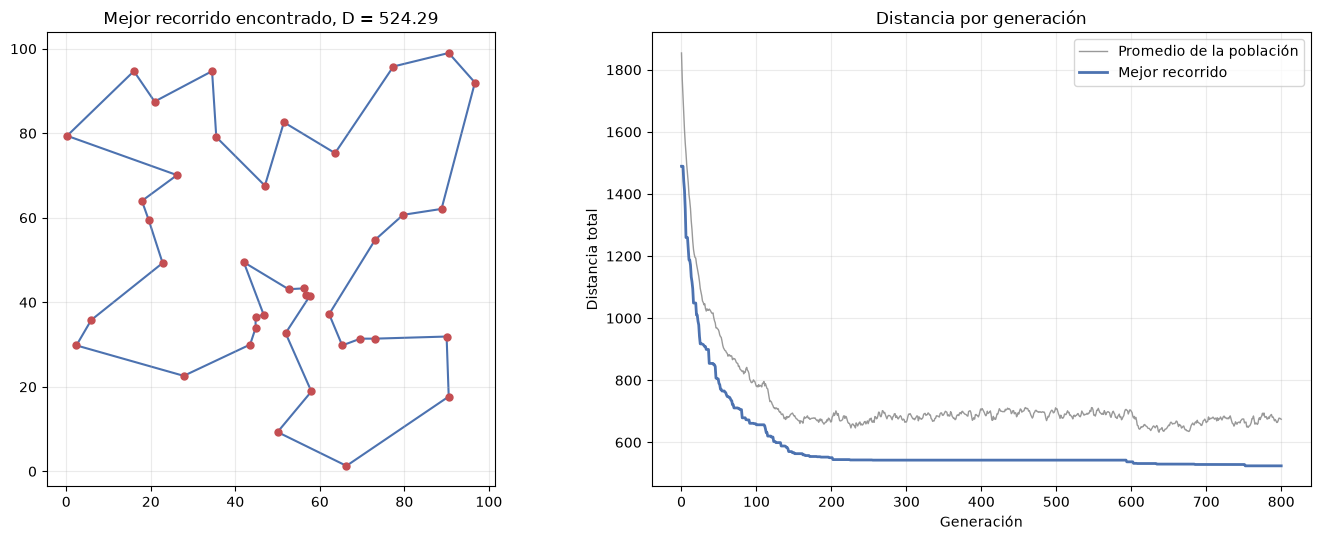

In [13]:
graficar_resultado(best, D, historial)

### Explicación de esta parte

En la gráfica de la izquierda los puntos rojos son las ciudades y la línea azul es el mejor recorrido. El recorrido no tiene líneas que se crucen. Eso es buena señal, porque cuando dos tramos se cruzan siempre se puede acortar el camino al quitar el cruce.

En la gráfica de la derecha la línea azul es la distancia del mejor recorrido que se lleva hasta cada generación. La bajada más fuerte pasa al inicio. La distancia baja de 1489.32 a 656.59 en las primeras 100 generaciones y llega a 550.59 en la generación 200. Entre las generaciones 255 y 593 se queda en 542.73. En la generación 594 aparece un recorrido mejor y la distancia sigue bajando hasta 524.29.

Ese tramo plano que después vuelve a bajar muestra por qué es importante cuidar la diversidad. La línea gris es el promedio de la población. Durante ese tramo se mantiene entre 630 y 715, lejos de la línea azul. O sea que la población todavía tenía recorridos distintos al mejor, y de ellos salió la combinación que permitió seguir mejorando.

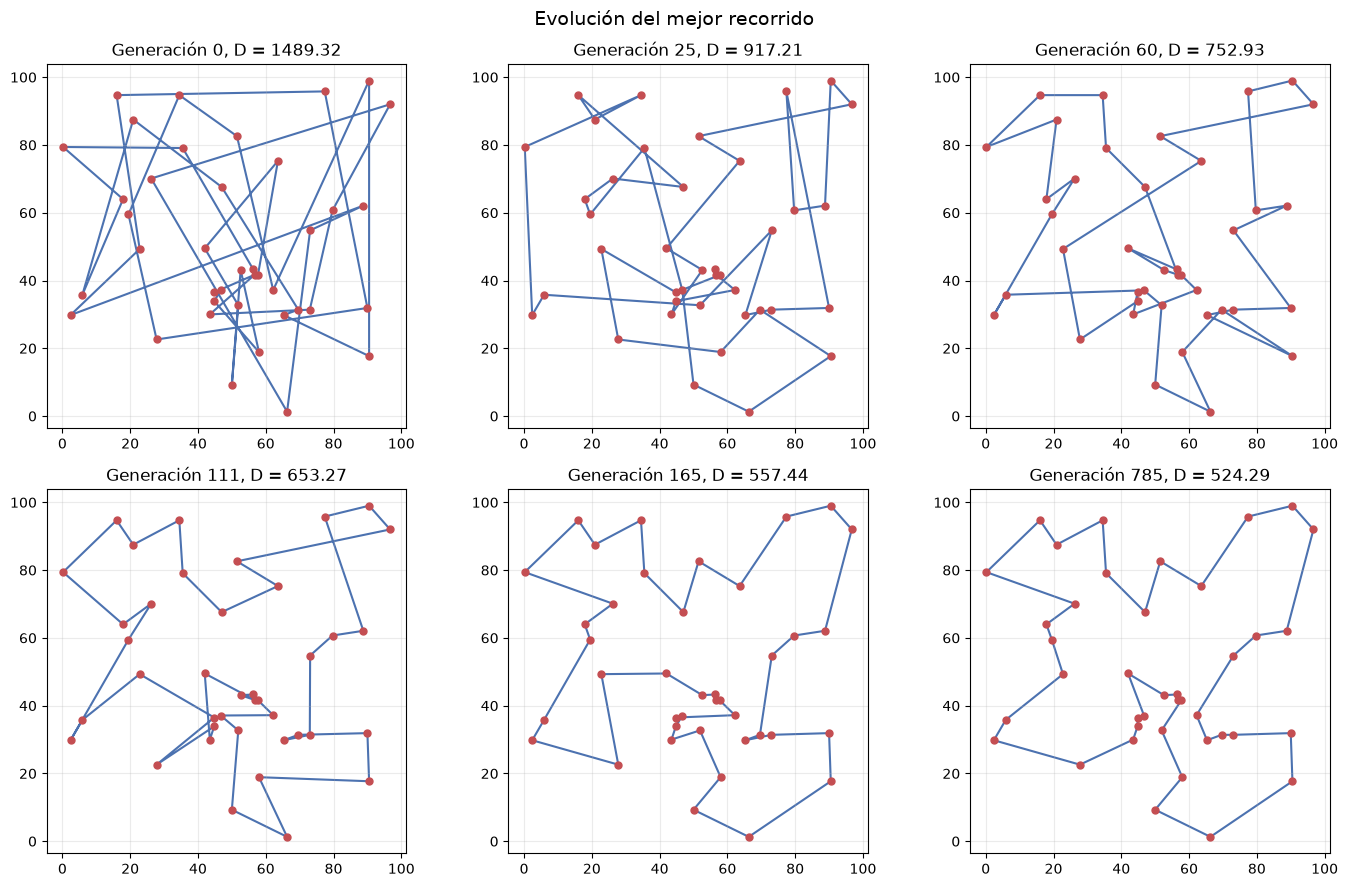

In [14]:
graficar_evolucion(historial)

### Explicación de esta parte

Los seis cuadros son el mejor recorrido en distintos momentos de la misma corrida. En la generación 0 el recorrido es al azar y las líneas atraviesan todo el mapa. En la generación 25 la distancia ya bajó a 917.21, aunque todavía hay muchos cruces. En las generaciones 60 y 111 el recorrido se va ordenando por zonas y quedan pocos tramos largos. En la generación 165 casi no hay cruces y la distancia es 557.44. El último cuadro es el resultado final, con una distancia de 524.29.

### Simulación

La siguiente celda crea la animación, la guarda en el archivo `evolucion_tsp.gif` y la muestra con botones para pausarla y avanzar cuadro por cuadro.

In [15]:
animacion = animar_evolucion(historial, archivo="evolucion_tsp.gif")
HTML(animacion.to_jshtml())

### Explicación de esta parte

El lado izquierdo muestra el mejor recorrido de cada momento y el lado derecho la distancia que le toca. El punto rojo marca la generación que se está viendo. Al inicio los cuadros cambian mucho porque casi cada generación trae un recorrido mejor. Hacia el final los cambios son ajustes pequeños entre ciudades vecinas.

## 12. Ejemplo con una matriz de distancias

Ahora se resuelve el mismo problema dando solo la matriz de distancias. La matriz se guarda en el archivo `matriz_ejemplo.csv` y al algoritmo se le da ese archivo, sin las coordenadas. Se usan los mismos parámetros y la misma semilla de la sección anterior.

Tamaño de la matriz leída: (40, 40)
Distancia total con la matriz como entrada      D = 524.2905
Distancia total con las coordenadas como entrada D = 524.2905
Se obtuvo el mismo recorrido: True
Diferencia máxima entre las distancias del dibujo y las de la matriz: 8.53e-14


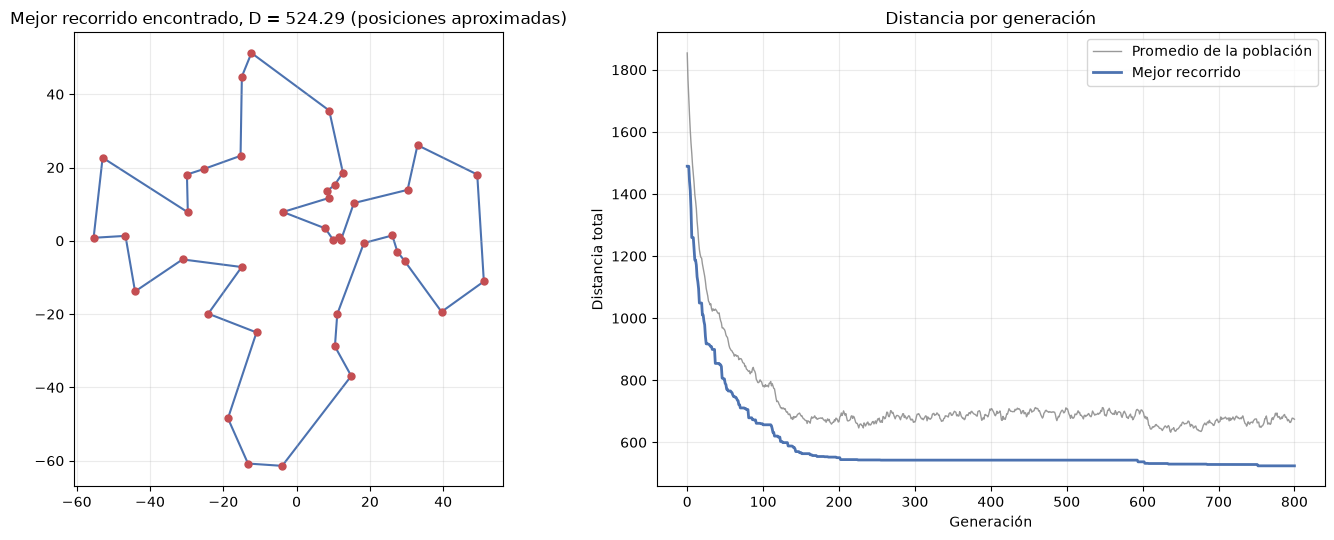

In [16]:
matriz_ejemplo, _ = cargar_problema("ciudades_ejemplo.csv")
np.savetxt("matriz_ejemplo.csv", matriz_ejemplo, delimiter=",")

best_matriz, D_matriz, historial_matriz = algoritmo_genetico_tsp(
    "matriz_ejemplo.csv",
    N=200,
    maxIter=800,
    seleccion="torneo",
    k=3,
    s=0.05,
    c=0.70,
    m=0.25,
    semilla=1,
)

print(f"Tamaño de la matriz leída: {matriz_ejemplo.shape}")
print(f"Distancia total con la matriz como entrada      D = {D_matriz:.4f}")
print(f"Distancia total con las coordenadas como entrada D = {D:.4f}")
print("Se obtuvo el mismo recorrido:", np.array_equal(best, best_matriz))

error = np.abs(matriz_de_distancias(historial_matriz["posiciones"]) - matriz_ejemplo).max()
print(f"Diferencia máxima entre las distancias del dibujo y las de la matriz: {error:.2e}")

graficar_resultado(best_matriz, D_matriz, historial_matriz)

### Explicación de esta parte

La matriz de $40 \times 40$ se guarda en un archivo. `cargar_problema` la reconoce como matriz de distancias porque es cuadrada, simétrica y tiene ceros en la diagonal. En esta corrida el algoritmo no recibe ninguna coordenada.

El resultado es el mismo de la sección anterior, con el mismo recorrido y $D = 524.29$. Así tenía que salir, porque la matriz tiene las mismas distancias y se usó la misma semilla. Con esto se comprueba que al algoritmo le da igual cuál de las dos formas de entrada reciba.

Para dibujar se usaron las posiciones que calcula `posiciones_aproximadas`. El mapa sale girado y volteado comparado con el original, porque una matriz de distancias no dice hacia dónde queda el norte. Las distancias entre los puntos dibujados son las mismas de la matriz, con una diferencia máxima cercana a $10^{-13}$. En este caso el dibujo sale exacto porque la matriz viene de puntos en un plano. Si la matriz viniera de otro lado, por ejemplo de distancias por carretera, el dibujo sería solo parecido. Por eso el título lo avisa.

## 13. Comparación de los tipos de selección

Se corre el algoritmo con cada uno de los cuatro tipos de selección en el problema de 40 ciudades. Los demás parámetros se dejan iguales, con $N = 200$, 500 generaciones, $s = 0.05$, $c = 0.70$ y $m = 0.25$. Como el resultado depende del azar, cada tipo se repite con 8 semillas.

Configuración                         Mejor  Mediana     Peor  Diversidad final
Torneo (k = 3)                       524.29   526.24   543.43            19.4 %
Ranking lineal                       524.36   538.48   559.90            26.4 %
Fitness (1/D)                        562.10   583.63   627.65            45.8 %
Elitismo (10 mejores)                524.29   526.22   531.33            11.9 %


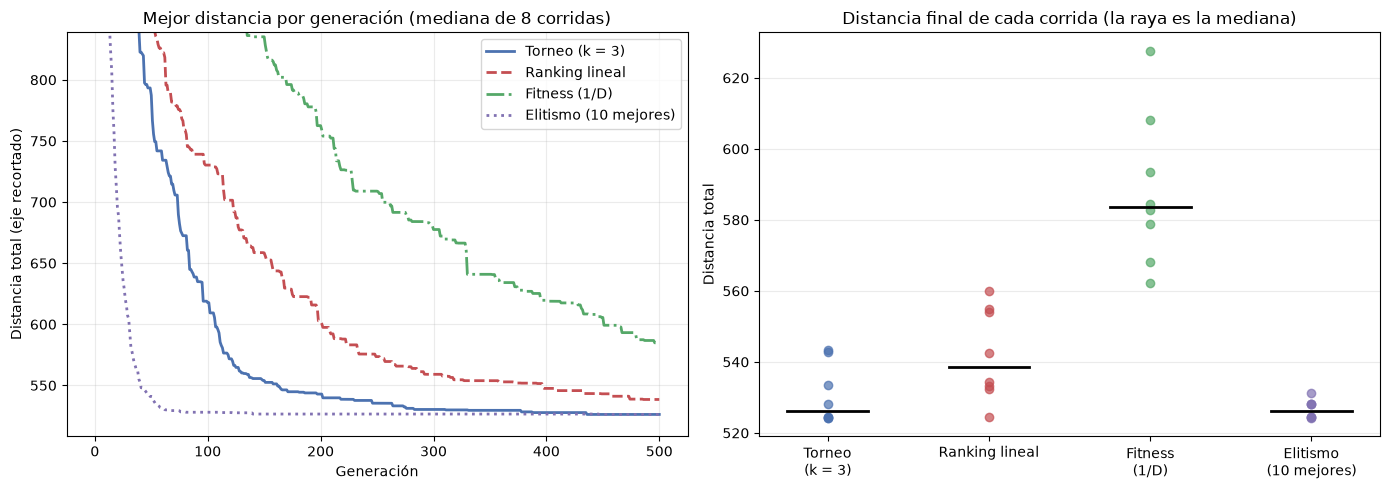

In [17]:
def repetir(entrada, semillas, **parametros):
    """Corre el algoritmo con varias semillas y resume los resultados."""
    finales, curvas, diversidades = [], [], []
    for semilla in semillas:
        _, D_final, h = algoritmo_genetico_tsp(entrada, semilla=semilla, **parametros)
        finales.append(D_final)
        curvas.append(h["mejor"])
        diversidades.append(h["diversidad"])
    return {
        "finales": np.array(finales),
        "mejor": np.median(curvas, axis=0),
        "diversidad": np.mean(diversidades, axis=0),
    }


def imprimir_tabla(resultados):
    print(f"{'Configuración':34s} {'Mejor':>8s} {'Mediana':>8s} {'Peor':>8s} {'Diversidad final':>17s}")
    for nombre, r in resultados.items():
        print(f"{nombre:34s} {r['finales'].min():8.2f} {np.median(r['finales']):8.2f} "
              f"{r['finales'].max():8.2f} {r['diversidad'][-1]:15.1f} %")


semillas = range(8)
esquemas = {
    "Torneo (k = 3)": dict(seleccion="torneo", k=3),
    "Ranking lineal": dict(seleccion="ranking", f="lineal"),
    "Fitness (1/D)": dict(seleccion="fitness", f="inversa"),
    "Elitismo (10 mejores)": dict(seleccion="elitismo"),
}
estilos = ["-", "--", "-.", ":"]
colores = [AZUL, ROJO, VERDE, "#8172B2"]

resultados_seleccion = {
    nombre: repetir(ciudades, semillas, N=200, maxIter=500, **opciones)
    for nombre, opciones in esquemas.items()
}
imprimir_tabla(resultados_seleccion)

mejor_global = min(r["finales"].min() for r in resultados_seleccion.values())
fig, (ax_curvas, ax_finales) = plt.subplots(1, 2, figsize=(14, 5))
for (nombre, r), estilo, color in zip(resultados_seleccion.items(), estilos, colores):
    ax_curvas.plot(r["mejor"], estilo, color=color, linewidth=2, label=nombre)
ax_curvas.set_ylim(0.97 * mejor_global, 1.6 * mejor_global)
ax_curvas.set_title("Mejor distancia por generación (mediana de 8 corridas)")
ax_curvas.set_xlabel("Generación")
ax_curvas.set_ylabel("Distancia total (eje recortado)")
ax_curvas.legend()
ax_curvas.grid(alpha=0.25)

for posicion, ((nombre, r), color) in enumerate(zip(resultados_seleccion.items(), colores)):
    ax_finales.plot(np.full(len(r["finales"]), posicion), r["finales"], "o", color=color, alpha=0.7)
    ax_finales.plot([posicion - 0.25, posicion + 0.25], [np.median(r["finales"])] * 2, color="black", linewidth=2)
ax_finales.set_xticks(range(len(esquemas)), [nombre.replace(" (", "\n(") for nombre in esquemas])
ax_finales.set_title("Distancia final de cada corrida (la raya es la mediana)")
ax_finales.set_ylabel("Distancia total")
ax_finales.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

### Explicación de esta parte

`repetir` corre el algoritmo una vez por cada semilla y guarda la distancia final de cada corrida. Para las líneas de la gráfica usa la mediana de las 8 corridas en cada generación. La mediana es el valor que queda en medio cuando los resultados se ordenan de menor a mayor. La tabla tiene la mejor distancia final, la mediana y la peor, junto con la diversidad promedio al terminar.

El torneo y el elitismo dan los mejores resultados, con medianas de 526.24 y 526.22. La diferencia entre los dos es más pequeña que lo que cambia el resultado de una corrida a otra. Entonces con 8 semillas no se puede decir que uno sea mejor que el otro. Lo que sí se ve en la gráfica de la izquierda es que el elitismo baja más rápido, porque solo cruza a los 10 mejores. También termina con la diversidad más baja, que es 11.9 %.

El ranking lineal queda en medio, con una mediana de 538.48. A las 500 generaciones todavía sigue bajando.

La selección por fitness con $1/D$ es la más lenta. Su mediana es 583.63. Su mejor corrida dio 562.10, que es peor que la peor corrida de cualquiera de los otros tres tipos. Es lo mismo que se vio en la gráfica de la sección 4. Como los inversos de las distancias se parecen tanto, los buenos recorridos casi no tienen ventaja. Su diversidad final es la más alta, con 45.8 %, porque la población casi no se junta alrededor de los mejores.

Por estos resultados, el tipo de selección que trae la función si el usuario no escoge otro es el torneo con $k = 3$. Llega a las mejores distancias y conserva más diversidad que el elitismo.

## 14. Efecto del control de diversidad

El enunciado pide cuidar que la población no pierda su diversidad muy rápido. Para revisar si el control de recorridos repetidos ayuda en eso, se comparan cuatro casos. Los dos primeros usan los parámetros que trae la función, con el control y sin el control. En la tabla y en la gráfica aparecen con el nombre "Por defecto". Los otros dos favorecen mucho más a los mejores y usan poca mutación, con $k = 10$, $c = 0.93$ y $m = 0.02$, también con el control y sin el control. Esos aparecen con el nombre "Presión alta". Cada caso se repite con 8 semillas.

Configuración                         Mejor  Mediana     Peor  Diversidad final
Por defecto, con control             524.29   526.24   543.43            19.4 %
Por defecto, sin control             524.29   528.86   554.20             1.5 %
Presión alta, con control            524.36   524.43   554.76            14.6 %
Presión alta, sin control            537.80   553.83   606.11             0.1 %


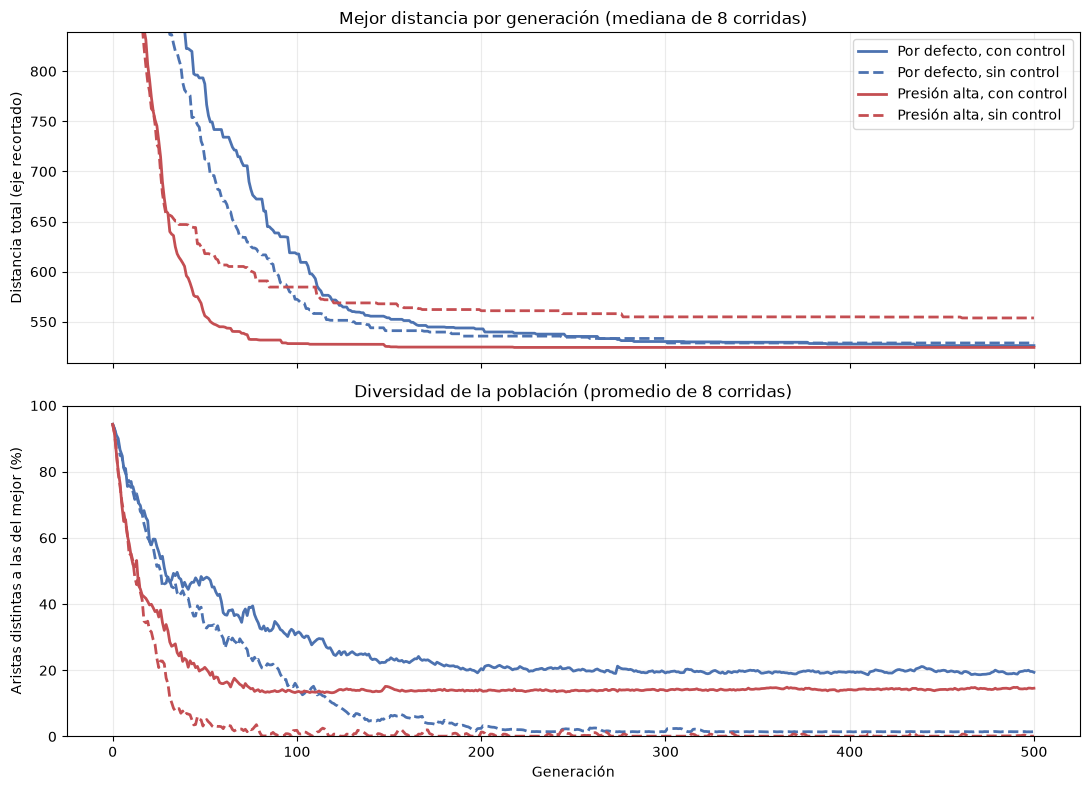

In [18]:
alta_presion = dict(k=10, s=0.05, c=0.93, m=0.02)
configuraciones = {
    "Por defecto, con control": dict(evitar_clones=True),
    "Por defecto, sin control": dict(evitar_clones=False),
    "Presión alta, con control": dict(evitar_clones=True, **alta_presion),
    "Presión alta, sin control": dict(evitar_clones=False, **alta_presion),
}
formatos = [(AZUL, "-"), (AZUL, "--"), (ROJO, "-"), (ROJO, "--")]

resultados_diversidad = {
    nombre: repetir(ciudades, semillas, N=200, maxIter=500, **opciones)
    for nombre, opciones in configuraciones.items()
}
imprimir_tabla(resultados_diversidad)

mejor_global = min(r["finales"].min() for r in resultados_diversidad.values())
fig, (ax_dist, ax_div) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
for (nombre, r), (color, estilo) in zip(resultados_diversidad.items(), formatos):
    ax_dist.plot(r["mejor"], estilo, color=color, linewidth=2, label=nombre)
    ax_div.plot(r["diversidad"], estilo, color=color, linewidth=2, label=nombre)
ax_dist.set_ylim(0.97 * mejor_global, 1.6 * mejor_global)
ax_dist.set_title("Mejor distancia por generación (mediana de 8 corridas)")
ax_dist.set_ylabel("Distancia total (eje recortado)")
ax_dist.legend()
ax_dist.grid(alpha=0.25)

ax_div.set_title("Diversidad de la población (promedio de 8 corridas)")
ax_div.set_xlabel("Generación")
ax_div.set_ylabel("Aristas distintas a las del mejor (%)")
ax_div.set_ylim(0, 100)
ax_div.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Explicación de esta parte

En la gráfica de abajo las líneas continuas son los casos con el control de recorridos repetidos y las líneas punteadas son los mismos casos sin el control.

Con los parámetros que trae la función, la diversidad se queda cerca de 19 % cuando el control está activo. Sin el control baja hasta 1.5 %, o sea que la población termina casi solo con copias del mejor recorrido. En la distancia la diferencia es pequeña, con medianas de 526.24 y 528.86, y es menor que lo que cambia el resultado de una corrida a otra. Hay que tomar en cuenta que esos parámetros ya traen un 25 % de mutación, que ayuda a reponer parte de la diversidad que se pierde.

Con presión alta y poca mutación la diferencia sí es clara. Sin el control, la diversidad baja de 5 % antes de la generación 100, termina en 0.1 % y la distancia se queda detenida. La mediana final es 553.83, un 5.6 % peor que la del mismo caso con el control, que es 524.43. Su mejor corrida dio 537.80 y no alcanza la mediana de ninguno de los otros tres casos.

Este es el problema que el enunciado pide evitar. Cuando la población pierde su diversidad muy rápido, el algoritmo se queda atascado en un recorrido que todavía se podía mejorar. Con el control activo, la misma presión alta mantiene una diversidad de 14.6 % y llega a buenos recorridos en pocas generaciones.

## 15. Conclusión

Se diseñó un algoritmo genético para el TSP que recibe coordenadas o una matriz de distancias, ya sea como listado o como archivo. El usuario puede cambiar el tamaño de la población, el número máximo de iteraciones, el tipo de selección con sus parámetros `k`, `s` y `f`, y las partes `c` y `m` de la población que se crean por cruce y por mutación. Los operadores son los que se vieron en clase para recorridos, que son los cruces OX y PMX y las mutaciones por inversión, intercambio, inserción y mezcla.

La función devuelve el mejor recorrido `best` y su distancia total `D`. La forma en que cambia el recorrido se ve en la animación y en los seis cuadros fijos. La forma en que baja la distancia se ve en la gráfica por generación.

En el problema de verificación de 10 ciudades el algoritmo encontró el óptimo exacto en las 10 corridas. En el ejemplo de 40 ciudades bajó la distancia de 1489.32 a 524.29, y dio el mismo resultado al recibir la matriz de distancias en lugar de las coordenadas.

De los cuatro tipos de selección, el torneo y el elitismo dieron los mejores recorridos y la selección por fitness con $1/D$ fue la más lenta. El control de recorridos repetidos mantuvo la diversidad de la población. Sin ese control y favoreciendo mucho a los mejores, la población se llenó de copias y la distancia final fue un 5.6 % peor.

La función `algoritmo_genetico_tsp` queda lista para usarse con otros problemas, y solo hay que cambiar la entrada.